In [1]:
import torch
import time
import ot

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA

from lib_pca.utils_sqrtm import sqrtm
from lib_pca.utils_plot import draw_cov
from lib_pca.lifted_pca import LiftedPCA, cost_pca
from lib_pca.distributional_pca import DistributionalPCA

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


The goal is to solve the Lifted PCA problem.This problem can be written as a Wasserstein barycenter with a particular cost and over a particular space. For instance, given $\nu_1,\dots,\nu_n\in \mathcal{P}(\mathbb{R}^d)$, it can be written as
\begin{equation}
    \min_{Q\in \mathcal{P}(\mathrm{St}(q,d))}\ \frac1n \sum_{i=1}^n W_c(\nu_i, Q),
\end{equation}
where $c(x,U)=\|x-UU^T x\|_2^2$ for $x\in \mathbb{R}^d, U\in \mathrm{St}(q,d)$. Equivalently, it can be written as
\begin{equation}
    \frac1n \sum_{i=1}^n \int \|x\|_2^2\ \mathrm{d}\nu_i(x) + \min_{\rho\in \mathcal{P}(\mathrm{Gr}(q,d))}\ \frac1n \sum_{i=1}^n W_\gamma(\mu_i, \rho),
\end{equation}
where $\mu_i = (x\mapsto xx^T)_\#\nu_i$, and $\gamma(A, P) = -\langle A, P\rangle_F$.

An generic algorithm to solve Wasserstein barycenters has been proposed (and analyzed) in [1]. It is a fixed-point approach, based on computing the ground barycenter. Hence, we need to compute using e.g. the first formulation
\begin{equation}
    \mathrm{argmin}_{U\in \mathrm{St}(q,d)}\ \frac1n \sum_{i=1}^n \|x - UU^T x\|_2^2,
\end{equation}
which is simply an Euclidean PCA.

[1] Tanguy, E., Delon, J., & Gozlan, N. (2024). Computing barycentres of measures for generic transport costs. arXiv preprint arXiv:2501.04016.

In [2]:
def plot(eig_lifted, eig_distr_pca, samples, means, Sigmas, title=None):

    for k in range(len(samples)):
        plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
        draw_cov(means[k], Sigmas[k], nstd=1)
    
    plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")
    
    ts = torch.linspace(-5, 5, 100)

    pc = ts[:,None] * eig_distr_pca[0][None]
    plt.plot(pc[:,0], pc[:,1], c="black", label="Distributional PCA")
    
    for k in range(len(eig_lifted)):
        pc = ts[:,None] * eig_lifted[k,:,0][None]

        if k == 0:
            plt.plot(pc[:,0], pc[:,1], c="orange", label="Lifted PCA")
        else:
            plt.plot(pc[:,0], pc[:,1], c="orange")

    if title is not None:
        plt.title(title)

    plt.legend()
    
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.show()

## Example of Niculae

On this type of data, maybe miss weights?

In [3]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(4)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

concat_samples = concat_samples - torch.mean(concat_samples, axis=0, keepdims=True)

In [4]:
# Using only 1 sample, should recover Distributional PCA?
lifted_pca = LiftedPCA(n_components=1, n_samples=1)
lifted_pca.fit(samples)

X_bar2 = lifted_pca.components_


# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_ # .numpy()

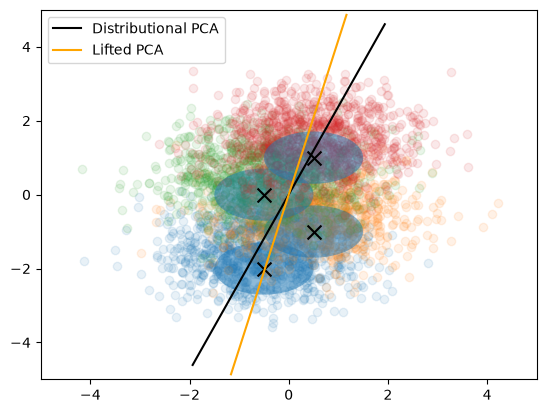

In [5]:
plot(X_bar2, eigenvectors_distributional, samples, means, Sigmas)

In [6]:
# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_ # .numpy()


# Using only 1 sample, should recover Distributional PCA?
lifted_pca = LiftedPCA(n_components=1, n_samples=1)
lifted_pca.fit(samples, X_init=eigenvectors_distributional[:,:,None])

X_bar2 = lifted_pca.components_

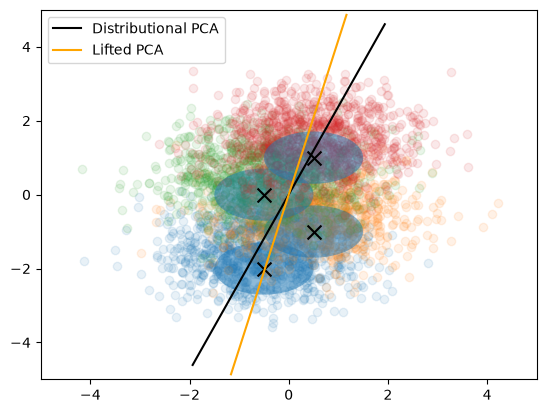

In [7]:
plot(X_bar2, eigenvectors_distributional, samples, means, Sigmas)

In [8]:
from lib_pca.lifted_pca import cost_pca

cost_lifted = cost_pca(X_bar2, concat_samples)
cost_distr = cost_pca(eigenvectors_distributional[:,:,None], concat_samples)

print(torch.mean(cost_lifted), torch.mean(cost_distr))

tensor(1.1696) tensor(1.1503)


In [9]:
print(torch.mean(cost_lifted), torch.mean(cost_distr))

tensor(1.1696) tensor(1.1503)


In [10]:
a = torch.ones(cost_lifted.shape[0]) / cost_lifted.shape[0]
b = torch.ones(cost_lifted.shape[1]) / cost_lifted.shape[1]
ot.emd2(a, b, cost_lifted)

tensor(1.1696)

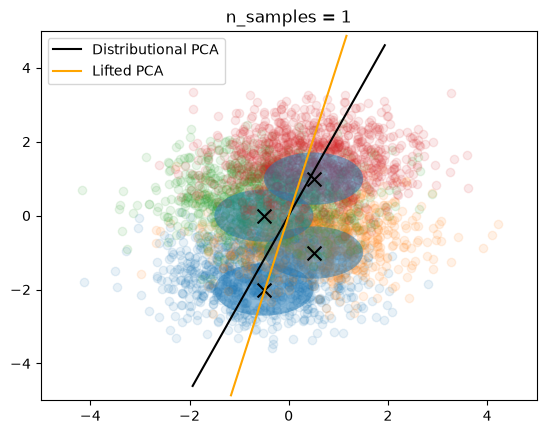

n=1 Lifted tensor(1.1696) Distributional tensor(1.1503)


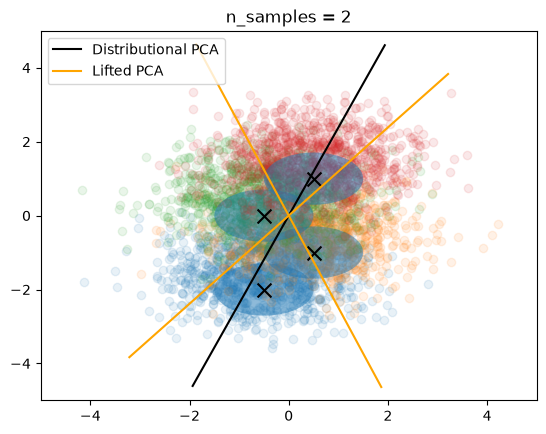

n=2 Lifted tensor(0.5087) Distributional tensor(1.1503)


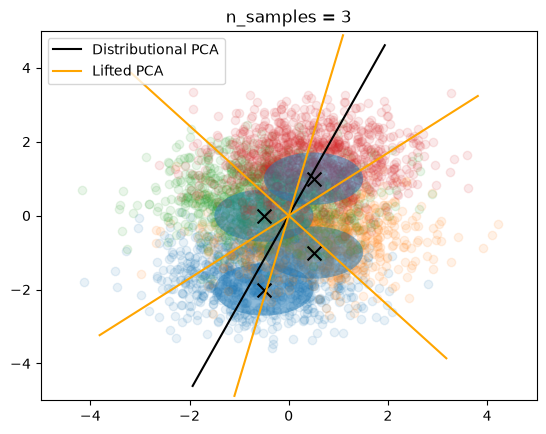

n=3 Lifted tensor(0.2779) Distributional tensor(1.1503)


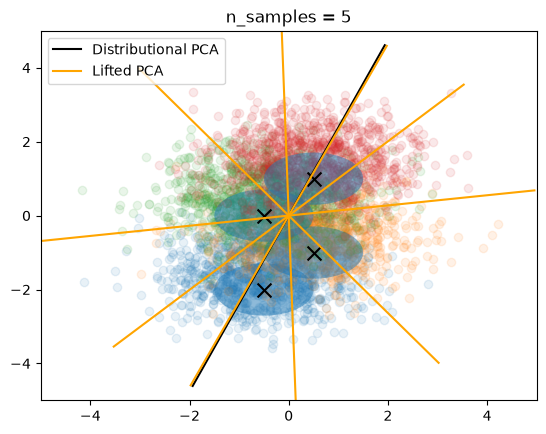

n=5 Lifted tensor(0.1161) Distributional tensor(1.1503)


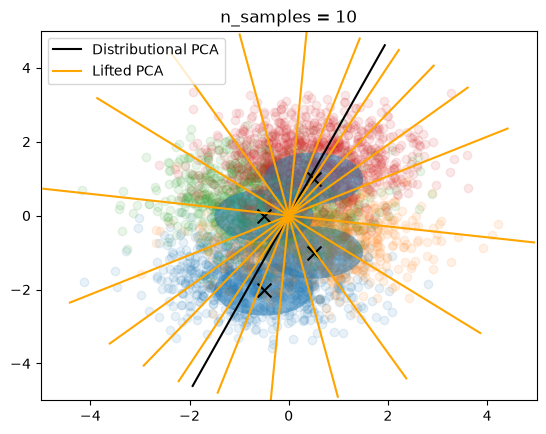

n=10 Lifted tensor(0.0394) Distributional tensor(1.1503)


In [11]:
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    
    X_bar2 = lifted_pca.components_
    
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(X_bar2, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))

    cost_lifted = cost_pca(X_bar2, concat_samples)
    cost_distr = cost_pca(eigenvectors_distributional[:,:,None], concat_samples)

    a_lifted = torch.ones(cost_lifted.shape[0]) / cost_lifted.shape[0]
    b_lifted = torch.ones(cost_lifted.shape[1]) / cost_lifted.shape[1]

    a_distr = torch.ones(cost_distr.shape[0]) / cost_distr.shape[0]
    b_distr = torch.ones(cost_distr.shape[1]) / cost_distr.shape[1]

    print(
        "n="+str(n_samples), "Lifted",
        ot.emd2(a_lifted, b_lifted, cost_lifted), "Distributional",
        ot.emd2(a_distr, b_distr, cost_distr)
    )

## 1 Clear PC

In [12]:
n_distr = 100

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

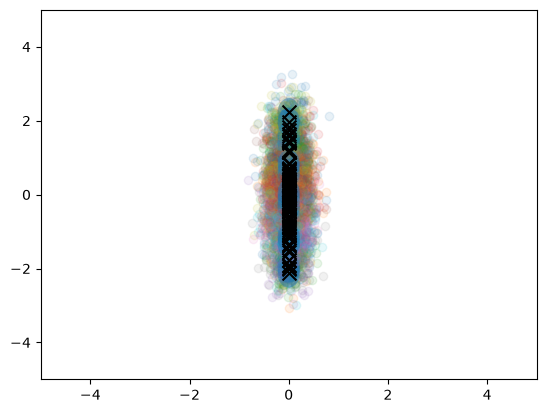

In [13]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

In [14]:
# Using only 1 sample, should recover Distributional PCA?
lifted_pca = LiftedPCA(n_components=1, n_samples=1)
lifted_pca.fit(samples)

X_bar2 = lifted_pca.components_


# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_# .numpy()

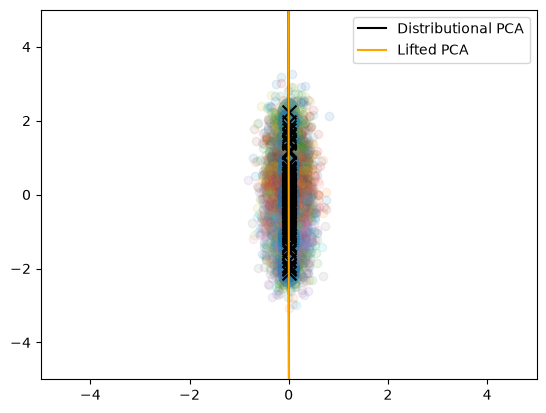

In [15]:
plot(X_bar2, eigenvectors_distributional, samples, means, Sigmas)

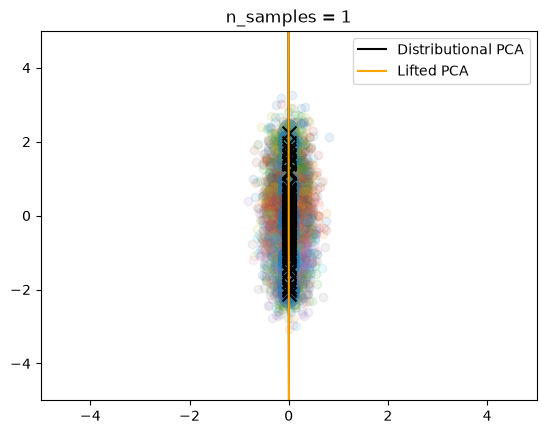

n=1 Lifted tensor(0.0502) Distributional tensor(0.0502)


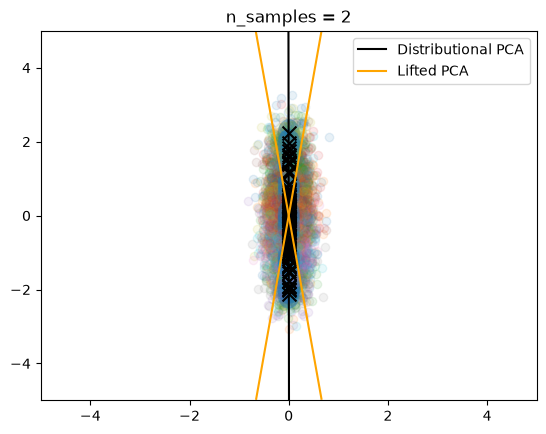

n=2 Lifted tensor(0.0297) Distributional tensor(0.0502)


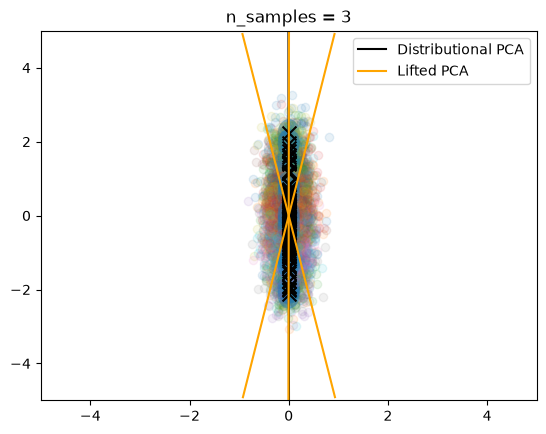

n=3 Lifted tensor(0.0227) Distributional tensor(0.0502)


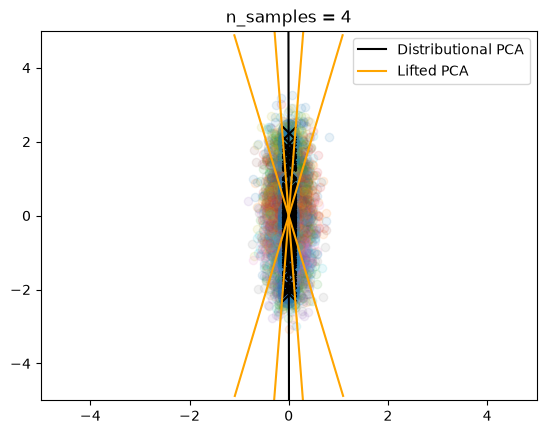

n=4 Lifted tensor(0.0195) Distributional tensor(0.0502)


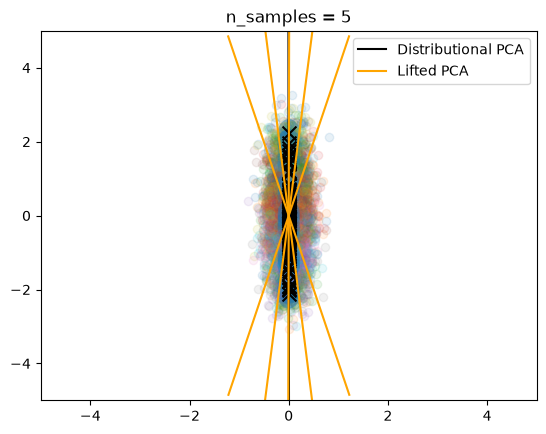

n=5 Lifted tensor(0.0176) Distributional tensor(0.0502)


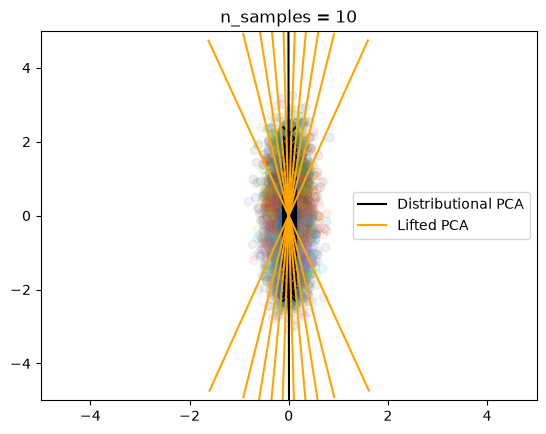

n=10 Lifted tensor(0.0142) Distributional tensor(0.0502)


In [16]:
for n_samples in [1, 2, 3, 4, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    
    X_bar2 = lifted_pca.components_
    
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(X_bar2, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))


    cost_lifted = cost_pca(X_bar2, concat_samples)
    cost_distr = cost_pca(eigenvectors_distributional[:,:,None], concat_samples)

    a_lifted = torch.ones(cost_lifted.shape[0]) / cost_lifted.shape[0]
    b_lifted = torch.ones(cost_lifted.shape[1]) / cost_lifted.shape[1]

    a_distr = torch.ones(cost_distr.shape[0]) / cost_distr.shape[0]
    b_distr = torch.ones(cost_distr.shape[1]) / cost_distr.shape[1]

    print(
        "n="+str(n_samples), "Lifted",
        ot.emd2(a_lifted, b_lifted, cost_lifted), "Distributional",
        ot.emd2(a_distr, b_distr, cost_distr)
    )

## 2 PCs

In [17]:
n_distr = 100

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

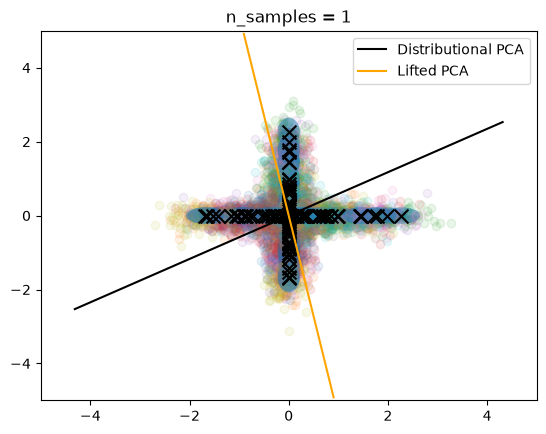

n=1 Lifted tensor(0.5633) Distributional tensor(0.5623)


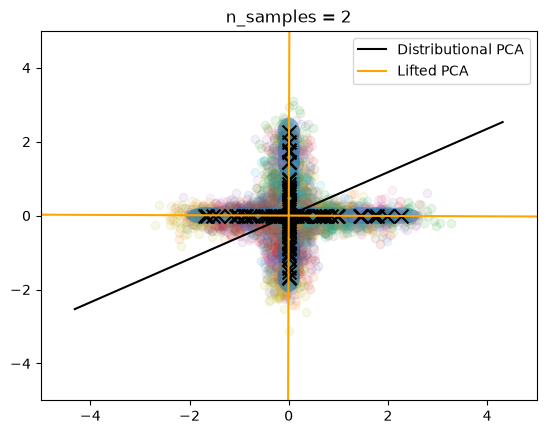

n=2 Lifted tensor(0.0416) Distributional tensor(0.5623)


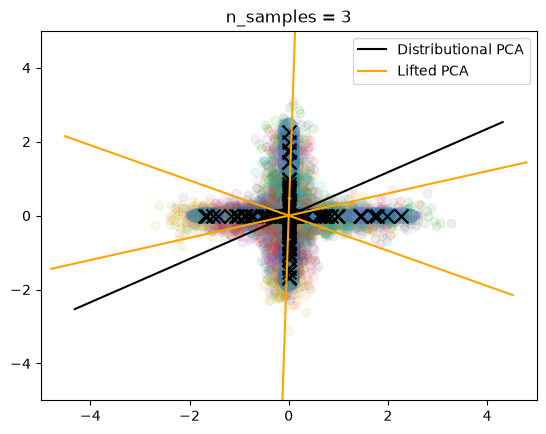

n=3 Lifted tensor(0.0599) Distributional tensor(0.5623)


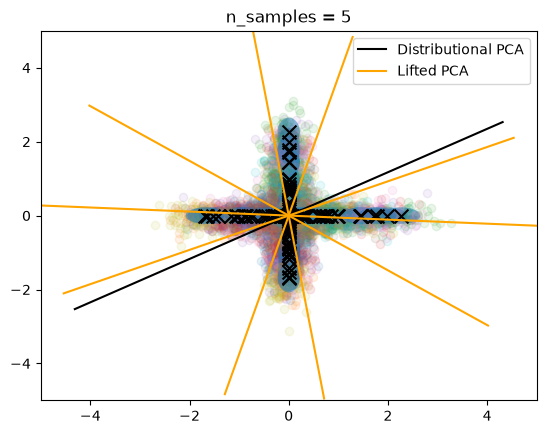

n=5 Lifted tensor(0.0234) Distributional tensor(0.5623)


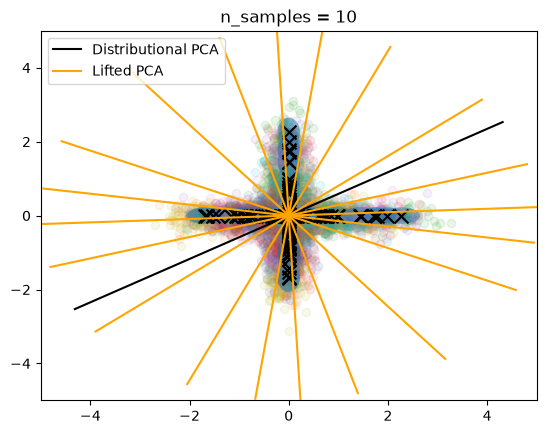

n=10 Lifted tensor(0.0065) Distributional tensor(0.5623)


In [18]:
for n_samples in [1, 2, 3, 5, 10]:
    lifted_pca = LiftedPCA(n_components=1, n_samples=n_samples)
    lifted_pca.fit(samples)
    
    X_bar2 = lifted_pca.components_
    
    
    # Distributional PCA
    pca_distributional = DistributionalPCA()
    pca_distributional.fit_from_samples(concat_samples, y_samples)
    eigenvectors_distributional = pca_distributional.components_# .numpy()

    plot(X_bar2, eigenvectors_distributional, samples, means, Sigmas, title="n_samples = "+str(n_samples))


    cost_lifted = cost_pca(X_bar2, concat_samples)
    cost_distr = cost_pca(eigenvectors_distributional[:,:,None], concat_samples)

    a_lifted = torch.ones(cost_lifted.shape[0]) / cost_lifted.shape[0]
    b_lifted = torch.ones(cost_lifted.shape[1]) / cost_lifted.shape[1]

    a_distr = torch.ones(cost_distr.shape[0]) / cost_distr.shape[0]
    b_distr = torch.ones(cost_distr.shape[1]) / cost_distr.shape[1]

    print(
        "n="+str(n_samples), "Lifted",
        ot.emd2(a_lifted, b_lifted, cost_lifted), "Distributional",
        ot.emd2(a_distr, b_distr, cost_distr)
    )

In [19]:
means = torch.randn((100, 2))

# Mean to center full distributions (to be equivalent with PCA)
full_mean = torch.mean(means, axis=0)

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k]) - full_mean

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(len(means))], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

concat_samples = concat_samples - torch.mean(concat_samples, axis=0, keepdims=True)

In [20]:
# Using only 1 sample, should recover Distributional PCA?
lifted_pca = LiftedPCA(n_components=1, n_samples=1)
lifted_pca.fit(samples)

X_bar2 = lifted_pca.components_


# Distributional PCA
pca_distributional = DistributionalPCA()
pca_distributional.fit_from_samples(concat_samples, y_samples)
eigenvectors_distributional = pca_distributional.components_ # .numpy()

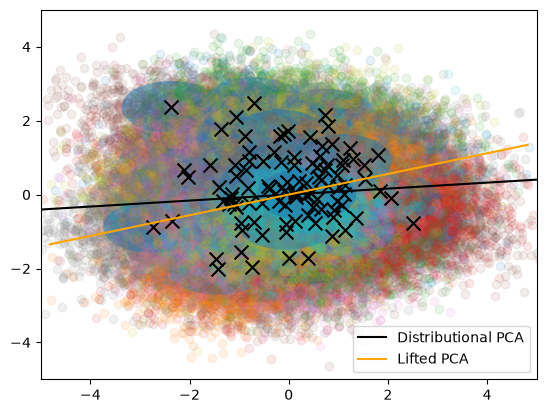

In [21]:
plot(X_bar2, eigenvectors_distributional, samples, means, Sigmas)

In [22]:
cost_lifted = cost_pca(X_bar2, concat_samples)
cost_distr = cost_pca(eigenvectors_distributional[:,:,None], concat_samples)

print(torch.mean(cost_lifted), torch.mean(cost_distr))

tensor(1.4267) tensor(1.4022)


In [ ]:
return

### Tests

In [14]:
from lib_pca.lifted_pca import cost_pca

In [24]:
def cost_pca(U, x):
    """
        Groundcost of the PCA (batched)

        Parameters
        ----------
        U : tensor of shape (n, d, n_components)
            Tensor containing the eigenvectors of the PCA for each of the n points.
        x : tensor of shape (m, d)
            Tensor containing the m points.

        Returns
        -------
        C : tensor of shape (n, m)
            Tensor containing the cost of the PCA for each of the n points and m points.
    """
    projs = torch.einsum("nij, nkj, ...mk -> ...nmi", U, U, x)
    C = torch.linalg.norm(x[None] - projs, axis=-1)**2
    return C

In [25]:
n_iter = 10

weights = [torch.ones(m.shape[0]) / m.shape[0] for m in samples]

for k in range(n_iter):
    lifted_pca = LiftedPCA(n_components=1, n_samples=1)
    lifted_pca.fit(samples)
    X_bar = lifted_pca.components_

    print(X_bar.shape, samples.shape)
    
    M = cost_pca(X_bar, samples)
    print(M.shape)
    
    a = ot.bregman.barycenter(weights, M, 1)

torch.Size([1, 2, 1]) torch.Size([100, 50, 2])
torch.Size([100, 100, 50])


RuntimeError: The size of tensor a (100) must match the size of tensor b (50) at non-singleton dimension 1

In [22]:
len(weights)

100

In [12]:
n_components = 1

def B(x, n_components=n_components):
    n, d = x[0].shape
    pca = PCA(n_components)

    output = torch.zeros((n, d, n_components))

    for i in range(n):
        z = torch.concatenate([x[k][i][None] for k in range(len(x))], axis=0)
        pca.fit(z)
        eigenvectors = pca.components_
        output[i] = torch.from_numpy(eigenvectors.T)

    return output


def cost(U, x):
    projs = torch.einsum("nij, nkj, mk -> nmi", U, U, x)
    C = torch.linalg.norm(x[None] - projs, axis=-1)**2
    return C


n_distr = 4
cost_list = [cost for k in range(n_distr)]

In [13]:
## Data from https://arxiv.org/abs/2306.13503

m1, m2, m3, m4 = [-0.5, -2], [0.5, -1], [-0.5, 0], [0.5, 1]
means = torch.tensor([m1, m2, m3, m4])

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([1, 0.5]))
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 1000
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

y_samples = torch.from_numpy(np.concatenate([[k] * 1000 for k in range(4)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

b_list = torch.ones(4, 1000) / 1000  # weights of the 4 measures

In [14]:
# fixed_point_its = 5
# n_components = 1

# torch.manual_seed(42)
# X_init = torch.rand(10, d, n_components)

# stop_threshold = 1e-20  # stop threshold for fixed-point algo

# t0 = time.time()
# X_bar, a_bar, log_dict = ot.lp.free_support_barycenter_generic_costs(
#     samples,
#     b_list,
#     X_init,
#     cost_list,
#     B,
#     numItermax=fixed_point_its,
#     stopThr=stop_threshold,
#     method="true_fixed_point",
#     log=True,
#     clean_measure=False, # don't work because (n,d,d)
# )
# dt_true_fixed_point = time.time() - t0

In [15]:
# 1 Dirac
fixed_point_its = 5
stop_threshold = 1e-20  # stop threshold for fixed-point algo

torch.manual_seed(42)
X_init = torch.rand(1, d, n_components)

t0 = time.time()
X_bar2, log_dict2 = ot.lp.free_support_barycenter_generic_costs(
    samples,
    b_list,
    X_init,
    cost_list,
    B,
    numItermax=fixed_point_its,
    stopThr=stop_threshold,
    log=True,
)
dt_barycentric = time.time() - t0

In [16]:
X_bar2.shape

torch.Size([1, 2, 1])

In [17]:
X_bar2

tensor([[[0.2478],
         [0.9688]]])

In [18]:
Z = torch.randn(1, d, n_components)
X_init, _ = torch.linalg.qr(Z)
torch.linalg.norm(X_init)

tensor(1.0000)

/tmp/ipykernel_60676/1880126514.py:13: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  pc = ts[:,None] * eigenvectors_distributional[0][None]


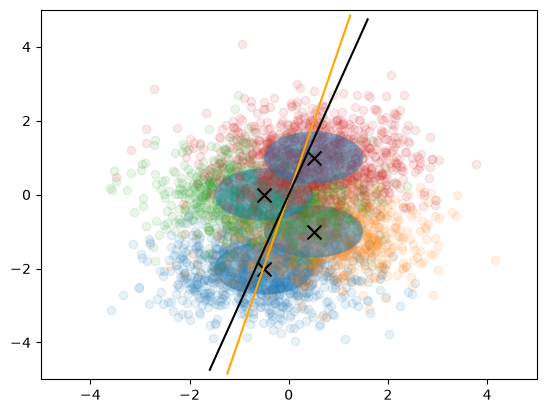

In [20]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

for k in range(len(X_bar2)):
    pc = ts[:,None] * X_bar2[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange")

pc = ts[:,None] * eigenvectors_distributional[0][None]
plt.plot(pc[:,0], pc[:,1], c="black")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

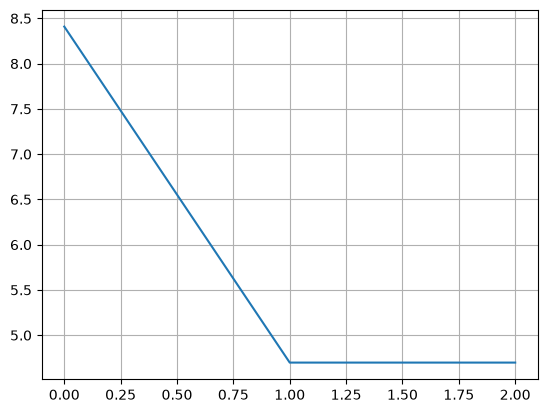

In [9]:
V_list2 = [V.item() for V in log_dict2["V_list"]]

plt.plot(V_list2)
plt.grid(True)
plt.show()

In [15]:
torch.linalg.norm(X_bar2[0,:,0])

tensor(1.)

In [37]:
# 2 Dirac
fixed_point_its = 10
stop_threshold = 1e-20  # stop threshold for fixed-point algo

torch.manual_seed(42)
X_init = torch.rand(2, d, n_components)

t0 = time.time()
X_bar2, log_dict2 = ot.lp.free_support_barycenter_generic_costs(
    samples,
    b_list,
    X_init,
    cost_list,
    B,
    numItermax=fixed_point_its,
    stopThr=stop_threshold,
    log=True,
)
dt_barycentric = time.time() - t0

In [38]:
X_bar2

tensor([[[ 0.6514],
         [ 0.7587]],

        [[-0.3290],
         [ 0.9443]]])

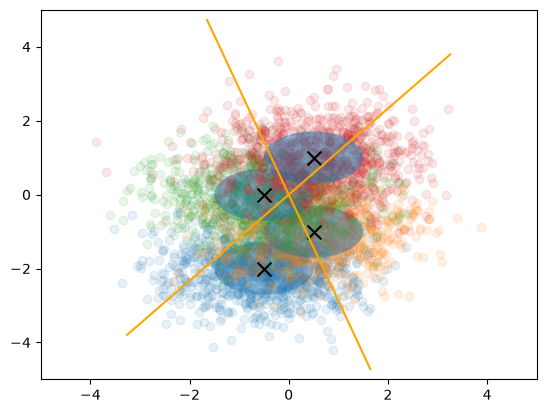

In [39]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

for k in range(len(X_bar2)):
    pc = ts[:,None] * X_bar2[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

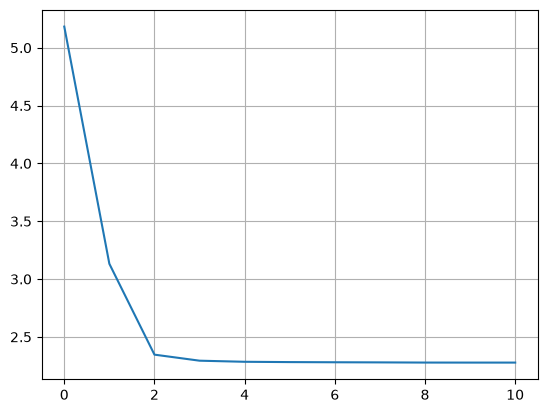

In [40]:
V_list2 = [V.item() for V in log_dict2["V_list"]]

plt.plot(V_list2)
plt.grid(True)
plt.show()

## 1 Clear PC

In [56]:
n_distr = 100
cost_list = [cost for k in range(n_distr)]

x0 = torch.zeros((n_distr, 1))
x1 = torch.randn((n_distr, 1))
means = torch.concatenate([x0, x1], axis=1)

# means = torch.randn((4, 2))

Sigma = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigmas = torch.stack([Sigma for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

b_list = torch.ones(len(means), n) / n  # weights each measure

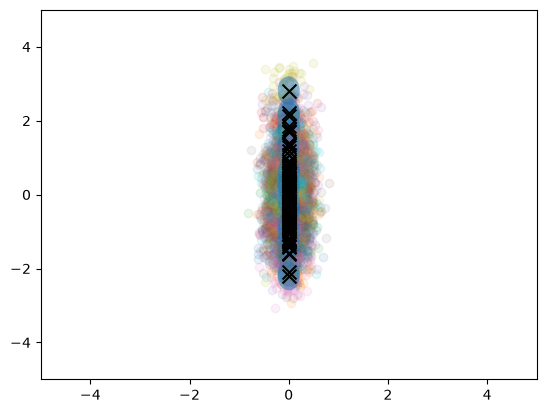

In [57]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

In [58]:
# 1 Dirac
fixed_point_its = 5
stop_threshold = 1e-20  # stop threshold for fixed-point algo

torch.manual_seed(42)
X_init = torch.rand(1, d, n_components)

t0 = time.time()
X_bar2, log_dict2 = ot.lp.free_support_barycenter_generic_costs(
    samples,
    b_list,
    X_init,
    cost_list,
    B,
    numItermax=fixed_point_its,
    stopThr=stop_threshold,
    log=True,
)
dt_barycentric = time.time() - t0

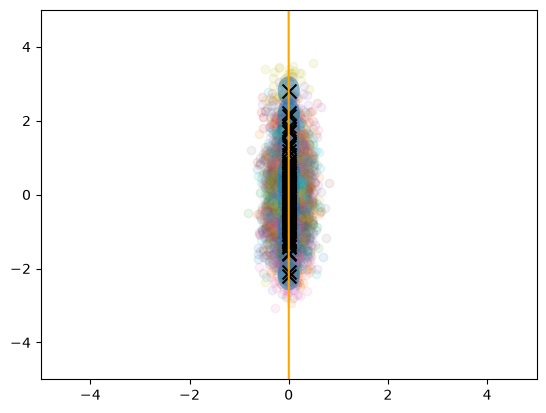

In [59]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

for k in range(len(X_bar2)):
    pc = ts[:,None] * X_bar2[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

In [69]:
# 2 Dirac
fixed_point_its = 10
stop_threshold = 1e-20  # stop threshold for fixed-point algo

torch.manual_seed(42)
X_init = torch.rand(5, d, n_components)

t0 = time.time()
X_bar2, log_dict2 = ot.lp.free_support_barycenter_generic_costs(
    samples,
    b_list,
    X_init,
    cost_list,
    B,
    numItermax=fixed_point_its,
    stopThr=stop_threshold,
    log=True,
)
dt_barycentric = time.time() - t0

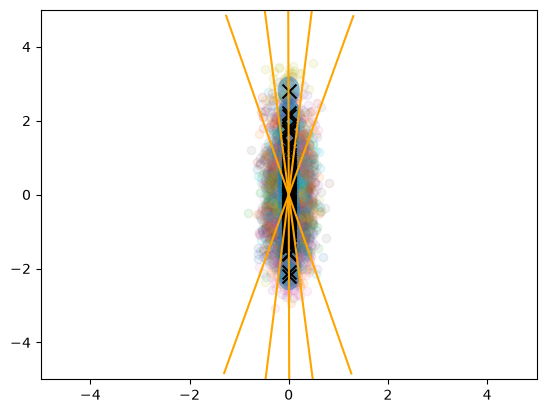

In [70]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

for k in range(len(X_bar2)):
    pc = ts[:,None] * X_bar2[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

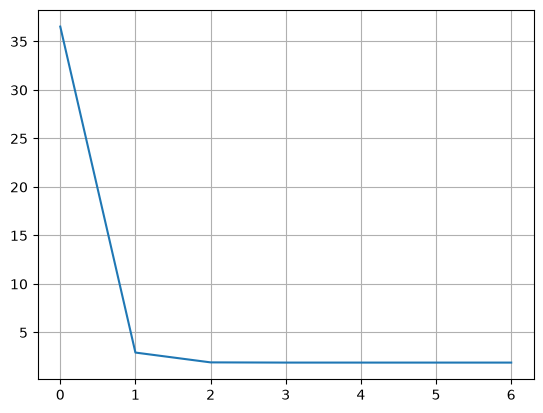

In [71]:
V_list2 = [V.item() for V in log_dict2["V_list"]]

plt.plot(V_list2)
plt.grid(True)
plt.show()

## 2 PCs

In [75]:
n_distr = 100
cost_list = [cost for k in range(n_distr)]

x0 = torch.zeros((n_distr//2, 1))
x1 = torch.randn((n_distr//2, 1))
means0 = torch.concatenate([x0, x1], axis=1)
means1 = torch.concatenate([x1, x0], axis=1)
means = torch.concatenate([means0, means1], axis=0)

# means = torch.randn((4, 2))

Sigma0 = torch.diag(torch.tensor([0.5, 1.5])) * 0.1
Sigma1 = torch.diag(torch.tensor([1.5, 0.5])) * 0.1
Sigmas = torch.stack([Sigma0 if i<50 else Sigma1 for i in range(len(means))])

# spd = SPDMatrices(2)
# samples = spd.random_point(n_samples=4)
# Sigmas = torch.from_numpy(samples).type(torch.float)

n = 50
d = 2
samples = torch.zeros((len(means), n, d))
for k in range(len(means)):
    samples[k] = means[k] + torch.randn(n, d) @ sqrtm(Sigmas[k])

y_samples = torch.from_numpy(np.concatenate([[k] * n for k in range(n_distr)], axis=0))
concat_samples = torch.cat([samples[k] for k in range(len(samples))], axis=0)

b_list = torch.ones(len(means), n) / n  # weights each measure

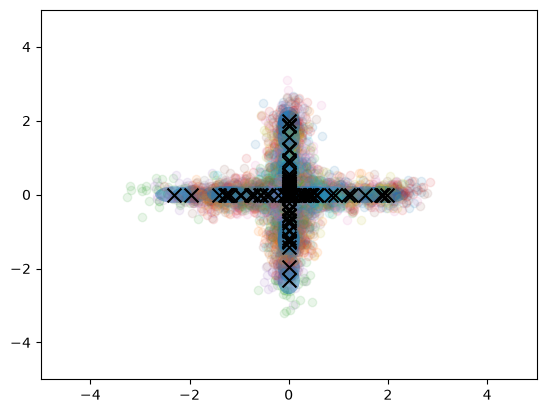

In [77]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

# for k in range(len(X_bar2)):
#     pc = ts[:,None] * X_bar2[k,:,0][None]
#     plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

In [78]:
# 1 Dirac
fixed_point_its = 5
stop_threshold = 1e-20  # stop threshold for fixed-point algo

torch.manual_seed(42)
X_init = torch.rand(1, d, n_components)

t0 = time.time()
X_bar2, log_dict2 = ot.lp.free_support_barycenter_generic_costs(
    samples,
    b_list,
    X_init,
    cost_list,
    B,
    numItermax=fixed_point_its,
    stopThr=stop_threshold,
    log=True,
)
dt_barycentric = time.time() - t0

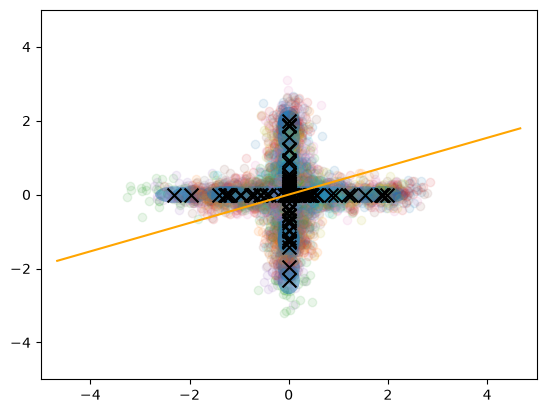

In [79]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

for k in range(len(X_bar2)):
    pc = ts[:,None] * X_bar2[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()

In [82]:
# 2 Dirac
fixed_point_its = 10
stop_threshold = 1e-20  # stop threshold for fixed-point algo

torch.manual_seed(42)
X_init = torch.rand(2, d, n_components)

t0 = time.time()
X_bar2, log_dict2 = ot.lp.free_support_barycenter_generic_costs(
    samples,
    b_list,
    X_init,
    cost_list,
    B,
    numItermax=fixed_point_its,
    stopThr=stop_threshold,
    log=True,
)
dt_barycentric = time.time() - t0

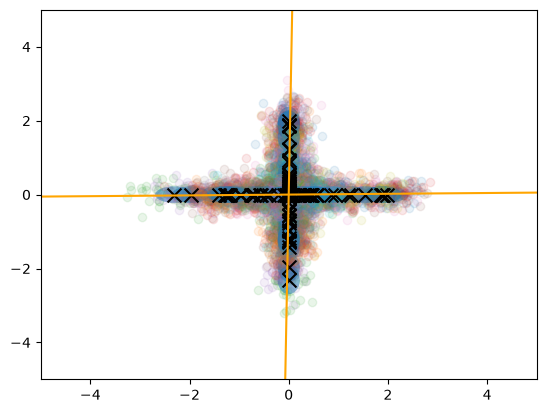

In [83]:
for k in range(len(means)):
    plt.scatter(samples[k][:, 0], samples[k][:,1], alpha=0.1)
    draw_cov(means[k], Sigmas[k], nstd=1)

plt.scatter(means[:, 0], means[:, 1], marker="x", s=100, c="k")

ts = torch.linspace(-5, 5, 100)

for k in range(len(X_bar2)):
    pc = ts[:,None] * X_bar2[k,:,0][None]
    plt.plot(pc[:,0], pc[:,1], c="orange")

plt.xlim(-5, 5)
plt.ylim(-5, 5)
plt.show()